# Projeto Prático 2 – Classificação de Conservantes com Perceptron Multicamadas (PMC)

Este projeto implementa uma rede neural Perceptron Multicamadas (PMC) para classificar tipos de conservantes (A, B ou C) com base em quatro variáveis físico-químicas.

## Configuração da Rede
- **Entradas:** 4 neurônios (teor de água, grau de acidez, temperatura, tensão interfacial)
- **Camada Oculta:** 15 neurônios
- **Saída:** 3 neurônios (Classes A, B, C)
- **Função de Ativação:** Logística (Sigmóide)
- **Taxa de Aprendizado ($\eta$):** 0,1
- **Precisão ($\varepsilon$):** $10^{-6}$

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Configuração para exibição de gráficos
%matplotlib inline

## 1. Carga e Preparação dos Dados

In [16]:
# Carregando os dados de treinamento
train_df = pd.read_csv('datasets/projeto-pratico-2.csv')

# Carregando os dados de teste
# O arquivo de teste possui aspas em cada linha, vamos tratar isso
try:
    # Tenta ler normalmente
    test_df = pd.read_csv('datasets/conjunto-testes-projeto-pratico-2.csv')
    if test_df.shape[1] == 1:
        raise ValueError("Lido como coluna única")
except:
    # Se falhar ou ler errado, limpa as aspas
    import io
    with open('datasets/conjunto-testes-projeto-pratico-2.csv', 'r') as f:
        lines = [line.replace('"', '').strip() for line in f.readlines()]
    test_df = pd.read_csv(io.StringIO('\n'.join(lines)))

print("Treinamento - Primeiras linhas:")
display(train_df.head())
print("\nTeste - Primeiras linhas:")
display(test_df.head())

Treinamento - Primeiras linhas:


,x1,x2,x3,x4,d1,d2,d3
0,0.3841,0.2021,0.0000,0.2438,1,0,0
1,0.1765,0.1613,0.3401,0.0843,1,0,0
2,0.3170,0.5786,0.3387,0.4192,0,1,0
3,0.2467,0.0337,0.2699,0.3454,1,0,0
4,0.6102,0.8192,0.4679,0.4762,0,1,0



Teste - Primeiras linhas:


,Amostra,x1,x2,x3,x4,d1,d2,d3
0,1,0.8622,0.7101,0.6236,0.7894,0,0,1
1,2,0.2741,0.1552,0.1333,0.1516,1,0,0
2,3,0.6772,0.8516,0.6543,0.7573,0,0,1
3,4,0.2178,0.5039,0.6415,0.5039,0,1,0
4,5,0.7260,0.7500,0.7007,0.4953,0,0,1


## 2. Implementação do Perceptron Multicamadas (PMC)

In [17]:
class MLP:
    def __init__(self, input_size, hidden_size, output_size, seed=None):
        if seed is not None:
            np.random.seed(seed)
        
        # Inicialização aleatória dos pesos (incluindo bias)
        # W1: Entrada -> Oculta (hidden_size x input_size + 1)
        # W2: Oculta -> Saída (output_size x hidden_size + 1)
        self.W1 = np.random.uniform(-0.5, 0.5, (hidden_size, input_size + 1))
        self.W2 = np.random.uniform(-0.5, 0.5, (output_size, hidden_size + 1))
        
        # Armazenamento de pesos iniciais para o segundo treinamento
        self.initial_W1 = self.W1.copy()
        self.initial_W2 = self.W2.copy()

    def reset_weights(self):
        self.W1 = self.initial_W1.copy()
        self.W2 = self.initial_W2.copy()

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def sigmoid_derivative(self, x):
        # x aqui é o valor já passado pela sigmóide
        return x * (1 - x)

    def train(self, X, D, eta=0.1, alpha=0.0, epsilon=1e-6, max_epochs=5000):
        N = X.shape[0]
        mse_history = []
        
        # Variáveis para Momentum
        delta_W1_prev = np.zeros_like(self.W1)
        delta_W2_prev = np.zeros_like(self.W2)
        
        start_time = time.time()
        
        for epoch in range(max_epochs):
            total_error = 0
            
            # Embaralhar dados a cada época (opcional, mas recomendado)
            indices = np.random.permutation(N)
            X_shuffled = X[indices]
            D_shuffled = D[indices]
            
            for i in range(N):
                x = X_shuffled[i].reshape(-1, 1)
                d = D_shuffled[i].reshape(-1, 1)
                
                # 1. Forward Pass
                # Camada de entrada (com bias)
                x_with_bias = np.vstack([[-1], x])
                
                # Camada oculta
                u1 = np.dot(self.W1, x_with_bias)
                y1 = self.sigmoid(u1)
                
                # Camada de saída (com bias)
                y1_with_bias = np.vstack([[-1], y1])
                u2 = np.dot(self.W2, y1_with_bias)
                y2 = self.sigmoid(u2)
                
                # Erro
                e = d - y2
                total_error += np.sum(e**2) * 0.5
                
                # 2. Backward Pass
                # Gradiente na camada de saída
                delta2 = e * self.sigmoid_derivative(y2)
                
                # Gradiente na camada oculta
                # Ignorar o peso do bias da camada de saída para propagar erro
                delta1 = self.sigmoid_derivative(y1) * np.dot(self.W2[:, 1:].T, delta2)
                
                # 3. Atualização de Pesos
                # W2
                delta_W2 = eta * np.dot(delta2, y1_with_bias.T) + alpha * delta_W2_prev
                self.W2 += delta_W2
                delta_W2_prev = delta_W2
                
                # W1
                delta_W1 = eta * np.dot(delta1, x_with_bias.T) + alpha * delta_W1_prev
                self.W1 += delta_W1
                delta_W1_prev = delta_W1
            
            mse = total_error / N
            mse_history.append(mse)
            
            if mse <= epsilon:
                break
                
        end_time = time.time()
        return mse_history, end_time - start_time, epoch + 1

    def predict(self, X):
        predictions = []
        for i in range(X.shape[0]):
            x = X[i].reshape(-1, 1)
            x_with_bias = np.vstack([[-1], x])
            
            y1 = self.sigmoid(np.dot(self.W1, x_with_bias))
            y1_with_bias = np.vstack([[-1], y1])
            y2 = self.sigmoid(np.dot(self.W2, y1_with_bias))
            
            # Pós-processamento (arredondamento simétrico)
            y_pos = (y2 >= 0.5).astype(int).flatten()
            predictions.append(y_pos)
            
        return np.array(predictions)

## 3. Execução dos Treinamentos

In [18]:
# Preparando X e D (Treinamento)
X_train = train_df[['x1', 'x2', 'x3', 'x4']].values
D_train = train_df[['d1', 'd2', 'd3']].values

# Inicializando a rede
mlp = MLP(input_size=4, hidden_size=15, output_size=3, seed=42)

print("Iniciando Treinamento 1: Backpropagation Convencional...")
history_conv, time_conv, epochs_conv = mlp.train(X_train, D_train, eta=0.1, alpha=0.0, epsilon=1e-6)
print(f"Finalizado em {epochs_conv} épocas. Tempo: {time_conv:.4f}s")

print("\nVoltando pesos iniciais...")
mlp.reset_weights()

print("Iniciando Treinamento 2: Backpropagation + Momentum...")
history_mom, time_mom, epochs_mom = mlp.train(X_train, D_train, eta=0.1, alpha=0.9, epsilon=1e-6)
print(f"Finalizado em {epochs_mom} épocas. Tempo: {time_mom:.4f}s")

Iniciando Treinamento 1: Backpropagation Convencional...
Finalizado em 5000 épocas. Tempo: 21.6386s

Voltando pesos iniciais...
Iniciando Treinamento 2: Backpropagation + Momentum...
Finalizado em 5000 épocas. Tempo: 20.7971s


## 4. Resultados e Gráficos

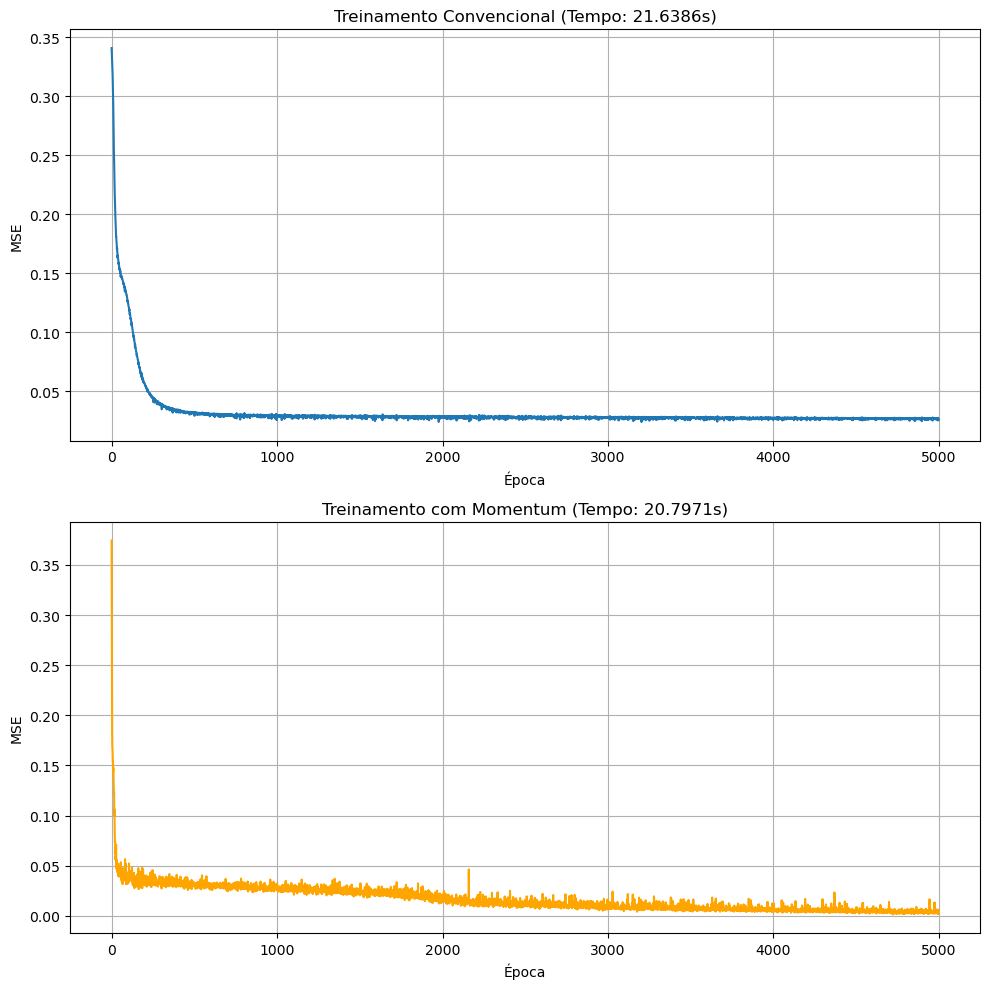

In [19]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10))

ax1.plot(history_conv)
ax1.set_title(f'Treinamento Convencional (Tempo: {time_conv:.4f}s)')
ax1.set_xlabel('Época')
ax1.set_ylabel('MSE')
ax1.grid(True)

ax2.plot(history_mom, color='orange')
ax2.set_title(f'Treinamento com Momentum (Tempo: {time_mom:.4f}s)')
ax2.set_xlabel('Época')
ax2.set_ylabel('MSE')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 5. Validação com Conjunto de Teste

In [20]:
# Preparando X e D (Teste)
X_test = test_df[['x1', 'x2', 'x3', 'x4']].values
D_test = test_df[['d1', 'd2', 'd3']].values

# Previsões
Y_test_pred = mlp.predict(X_test)

# Cálculo da taxa de acerto
correct = 0
for i in range(len(D_test)):
    if np.array_equal(Y_test_pred[i], D_test[i]):
        correct += 1

accuracy = (correct / len(D_test)) * 100

print(f"Total de amostras de teste: {len(D_test)}")
print(f"Amostras classificadas corretamente: {correct}")
print(f"Taxa de acerto: {accuracy:.2f}%")

# Exibindo as previsões comparadas aos valores reais
test_results = test_df.copy()
test_results['y1_pred'] = Y_test_pred[:, 0]
test_results['y2_pred'] = Y_test_pred[:, 1]
test_results['y3_pred'] = Y_test_pred[:, 2]

display(test_results)

Total de amostras de teste: 18
Amostras classificadas corretamente: 18
Taxa de acerto: 100.00%


,Amostra,x1,x2,x3,x4,d1,d2,d3,y1_pred,y2_pred,y3_pred
0,1,0.8622,0.7101,0.6236,0.7894,0,0,1,0,0,1
1,2,0.2741,0.1552,0.1333,0.1516,1,0,0,1,0,0
2,3,0.6772,0.8516,0.6543,0.7573,0,0,1,0,0,1
3,4,0.2178,0.5039,0.6415,0.5039,0,1,0,0,1,0
4,5,0.7260,0.7500,0.7007,0.4953,0,0,1,0,0,1
5,6,0.2473,0.2941,0.4248,0.3087,1,0,0,1,0,0
6,7,0.5682,0.5683,0.5054,0.4426,0,1,0,0,1,0
7,8,0.6566,0.6715,0.4952,0.3951,0,1,0,0,1,0
8,9,0.0705,0.4717,0.2921,0.2954,1,0,0,1,0,0
9,10,0.1187,0.2568,0.3140,0.3037,1,0,0,1,0,0


## 6. Comparação com Scikit-Learn (MLPClassifier)

Vamos comparar nossa implementação manual com o `MLPClassifier` para verificar a consistência dos resultados.

In [21]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Configurando o modelo do Scikit-Learn
# momentum=0.9 para comparar com o nosso segundo treinamento
sk_mlp = MLPClassifier(
    hidden_layer_sizes=(15,),
    activation='logistic',
    solver='sgd',
    learning_rate_init=0.1,
    momentum=0.9,
    tol=1e-6,
    max_iter=5000,
    random_state=42
)

# Treinamento
sk_mlp.fit(X_train, D_train)

# Predição no conjunto de teste
Y_pred_sk = sk_mlp.predict(X_test)

# Cálculo da Acurácia
accuracy_sk = accuracy_score(D_test, Y_pred_sk) * 100

print("--- Resultados Scikit-Learn ---")
print(f"Acurácia Final: {accuracy_sk:.2f}%")
print(f"Épocas até convergência: {sk_mlp.n_iter_}")

print("\n--- Comparação Final ---")
print(f"Acurácia Manual: {accuracy:.2f}%")
print(f"Acurácia Scikit-Learn: {accuracy_sk:.2f}%")

--- Resultados Scikit-Learn ---
Acurácia Final: 94.44%
Épocas até convergência: 5000

--- Comparação Final ---
Acurácia Manual: 100.00%
Acurácia Scikit-Learn: 94.44%


/home/enzosarmento/anaconda3/envs/Titanic/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


## 7. Abordagem com Deep Learning (Keras/TensorFlow)

Para problemas onde modelos lineares ou RNAs simples do scikit-learn não atingem a performance desejada, podemos utilizar o **Keras**. Ele oferece maior controle sobre a arquitetura, inicialização e otimizadores mais modernos (como Adam).

In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Definindo o modelo Keras
model_keras = Sequential([
    Dense(32, activation='relu', input_shape=(4,)),
    Dense(16, activation='relu'),
    Dense(3, activation='softmax')
])

model_keras.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# O Keras espera targets em formato one-hot para categorical_crossentropy
# Mas D_train já está em formato one-hot (d1, d2, d3)!
history_keras = model_keras.fit(
    X_train, D_train, 
    epochs=200, 
    batch_size=16, 
    verbose=0
)

# Predição e Avaliação
Y_pred_keras_raw = model_keras.predict(X_test)
Y_pred_keras = (Y_pred_keras_raw == Y_pred_keras_raw.max(axis=1, keepdims=True)).astype(int)

accuracy_keras = accuracy_score(D_test, Y_pred_keras) * 100

print("--- Resultados Keras (Deep Learning) ---")
print(f"Acurácia Final: {accuracy_keras:.2f}%")

print("\n--- Comparação Tripla ---")
print(f"Acurácia Manual (NumPy): {accuracy:.2f}%")
print(f"Acurácia Scikit-Learn: {accuracy_sk:.2f}%")
print(f"Acurácia Keras (Robustez): {accuracy_keras:.2f}%")

I0000 00:00:1777828242.552886   85070 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/enzosarmento/anaconda3/envs/Titanic/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
--- Resultados Keras (Deep Learning) ---
Acurácia Final: 100.00%

--- Comparação Tripla ---
Acurácia Manual (NumPy): 100.00%
Acurácia Scikit-Learn: 94.44%
Acurácia Keras (Robustez): 100.00%
